In [1]:
import numpy as  np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [3]:
df = sns.load_dataset('dowjones')
df.head(3)

,Date,Price
0,1914-12-01,55.00
1,1915-01-01,56.55
2,1915-02-01,56.00


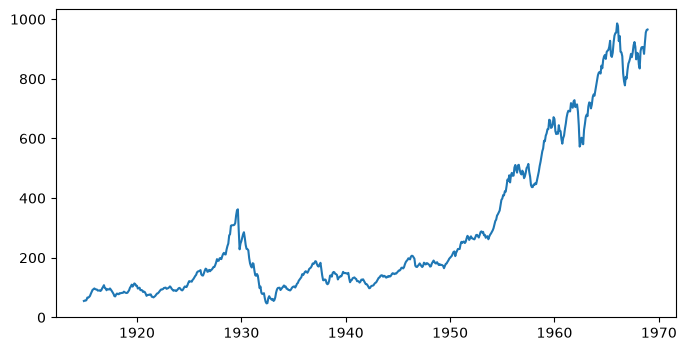

In [5]:
plt.figure(figsize=(8,4))
plt.plot(df['Date'],df['Price'])
plt.show()

In [6]:
df.isnull().sum()

Date     0
Price    0
dtype: int64

In [7]:
# 1. 'Date' column ko datetime format mein convert karein
df['Date'] = pd.to_datetime(df['Date'])

# 2. 'Date' ko index banayein
df.set_index('Date', inplace=True)

# 3. Check karein
print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
DatetimeIndex: 649 entries, 1914-12-01 to 1968-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   649 non-null    float64
dtypes: float64(1)
memory usage: 10.1 KB
None
            Price
Date             
1914-12-01  55.00
1915-01-01  56.55
1915-02-01  56.00
1915-03-01  58.30
1915-04-01  66.45


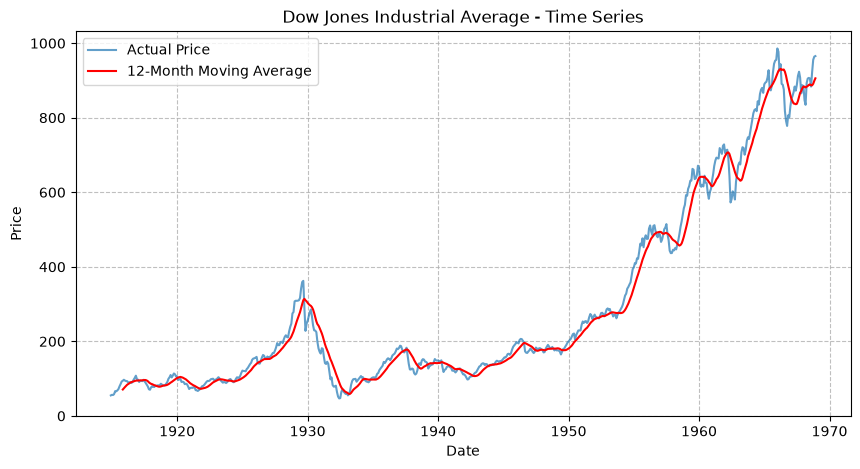

In [10]:
# 12-month moving average ke saath plot karein
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['Price'], label='Actual Price', alpha=0.7)
plt.plot(df.index, df['Price'].rolling(window=12).mean(), label='12-Month Moving Average', color='red')

plt.title('Dow Jones Industrial Average - Time Series')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.8)
plt.show()

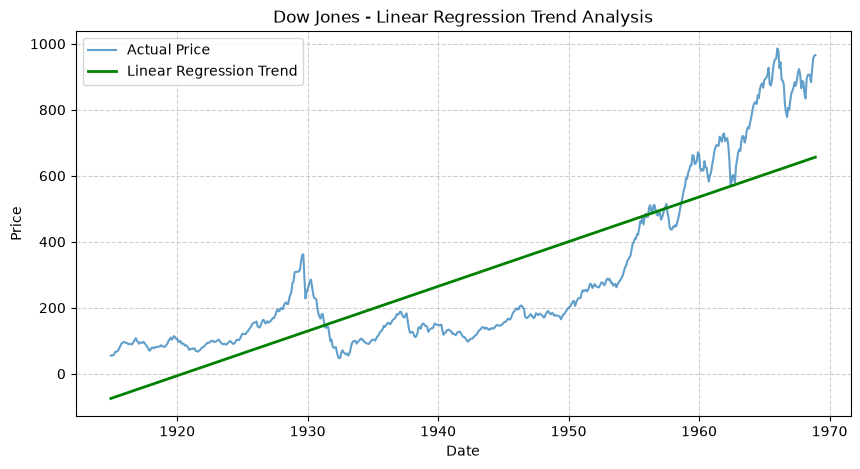

Slope (Har mahine ka growth rate): 1.1286
Intercept: -74.85


In [11]:
from sklearn.linear_model import LinearRegression
import numpy as np

# 1. Feature (X) create karein: Time step index (0, 1, 2, ... N-1)
# Linear trend ke liye numeric time step sabse best rehta hai
df['Time_Step'] = np.arange(len(df))

X = df[['Time_Step']]  # Features 2D DataFrame/Array hona chahiye
y = df['Price']        # Target variable

# 2. Linear Regression model fit karein
lr_model = LinearRegression()
lr_model.fit(X, y)

# 3. Trend line predict karein
df['LR_Trend'] = lr_model.predict(X)

# 4. Actual data ke saath Linear Regression trend plot karein
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['Price'], label='Actual Price', alpha=0.7)
plt.plot(df.index, df['LR_Trend'], label='Linear Regression Trend', color='green', linewidth=2)

plt.title('Dow Jones - Linear Regression Trend Analysis')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Model parameters print karein
print(f"Slope (Har mahine ka growth rate): {lr_model.coef_[0]:.4f}")
print(f"Intercept: {lr_model.intercept_:.2f}")

Train samples: 519, Test samples: 130
Test RMSE: 430.34
Test R2 Score: -8.8072


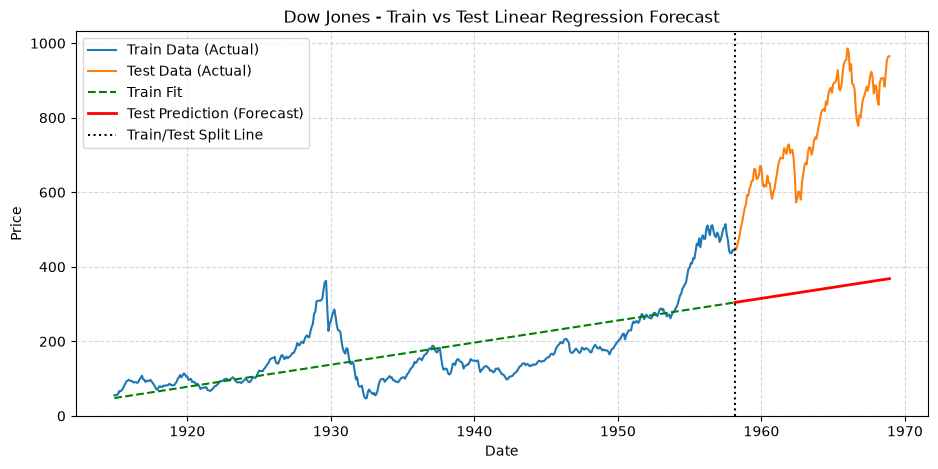

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

# 1. 80-20 Time-based Split (Bina shuffle kiye)
train_size = int(len(df) * 0.8)

train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

# Features aur Target alag karein
X_train = train_df[['Time_Step']]
y_train = train_df['Price']

X_test = test_df[['Time_Step']]
y_test = test_df['Price']

# 2. Model ko sirf Train data par train karein
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Dono par predictions lein
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 4. Evaluation Metrics (Test data par)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2 = r2_score(y_test, y_test_pred)

print(f"Train samples: {len(train_df)}, Test samples: {len(test_df)}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R2 Score: {r2:.4f}")

# 5. Train, Test aur Predictions ka visualization
plt.figure(figsize=(11, 5))
plt.plot(train_df.index, y_train, label='Train Data (Actual)', color='#1f77b4')
plt.plot(test_df.index, y_test, label='Test Data (Actual)', color='#ff7f0e')

# Predictions
plt.plot(train_df.index, y_train_pred, label='Train Fit', color='green', linestyle='--')
plt.plot(test_df.index, y_test_pred, label='Test Prediction (Forecast)', color='red', linewidth=2)

plt.axvline(x=test_df.index[0], color='black', linestyle=':', label='Train/Test Split Line')
plt.title('Dow Jones - Train vs Test Linear Regression Forecast')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()